In [6]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
import shap
import matplotlib.pyplot as plt

In [7]:
# ==============================================================================
# 1. LOAD GTFS-ENRICHED 10:1 STRATIFIED DATASET
# ==============================================================================
gtfs_file = os.path.join("..", "Datasets", "RZLT_Samples", "RZLT_AllCodes_10to1_WithGTFS.geojson")
if not os.path.exists(gtfs_file):
    gtfs_file = "RZLT_AllCodes_10to1_WithGTFS.geojson"

gdf = gpd.read_file(gtfs_file)
if gdf.crs != "EPSG:2157":
    gdf = gdf.to_crs(epsg=2157)

In [8]:
# ==============================================================================
# 2. GEOMETRY SHAPE & SPATIAL DENSITY FEATURE ENGINEERING
# ==============================================================================
area_m2 = gdf.geometry.area
perim_m = gdf.geometry.length

# Polsby-Popper Compactness: 1.0 = perfect circle, close to 0 = thin strip/road verge
gdf['SHAPE_COMPACTNESS'] = (4 * np.pi * area_m2) / np.maximum(perim_m ** 2, 1e-6)
gdf['PERIM_TO_AREA'] = perim_m / np.maximum(area_m2, 1e-6)
gdf['LOG_SITE_AREA'] = np.log1p(gdf['SITE_AREA'])

# Local spatial clustering: count of other sampled RZLT parcels within 500m
coords = np.column_stack([gdf['centroid_x'], gdf['centroid_y']])
parcel_tree = cKDTree(coords)
gdf['PARCELS_WITHIN_500M'] = [len(idx) - 1 for idx in parcel_tree.query_ball_point(coords, r=500.0)]

In [9]:
# ==============================================================================
# 3. 5-FOLD STRATIFIED CROSS-VALIDATION (LEAK-FREE)
# ==============================================================================
num_cols = [
    'SITE_AREA', 'LOG_SITE_AREA',
    'SHAPE_COMPACTNESS', 'PERIM_TO_AREA', 'PARCELS_WITHIN_500M',
    'DIST_TO_BUS_M', 'DIST_TO_RAIL_LUAS_M', 'DIST_TO_ANY_TRANSIT_M',
    'BUS_STOPS_WITHIN_500M', 'LOG_DIST_BUS', 'LOG_DIST_RAIL_LUAS'
]
num_cols = [c for c in num_cols if c in gdf.columns]
cat_cols = ['ZONE_GZT', 'LOCAL_AUTHORITY']

for c in cat_cols:
    gdf[c] = gdf[c].fillna("Unknown").astype(str).str.strip()

X_df = gdf[num_cols + cat_cols].copy()
y = gdf['target'].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros(len(y))
oof_preds = np.zeros(len(y))
fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_df, y), start=1):
    X_tr_raw, X_va_raw = X_df.iloc[train_idx], X_df.iloc[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    tr_cat = ohe.fit_transform(X_tr_raw[cat_cols])
    va_cat = ohe.transform(X_va_raw[cat_cols])

    X_tr = np.hstack([X_tr_raw[num_cols].values, tr_cat])
    X_va = np.hstack([X_va_raw[num_cols].values, va_cat])

    fold_spw = (y_tr == 0).sum() / (y_tr == 1).sum()

    model = XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=fold_spw,
        eval_metric='aucpr',
        random_state=42 + fold,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)

    probs = model.predict_proba(X_va)[:, 1]
    oof_probs[val_idx] = probs
    oof_preds[val_idx] = (probs >= 0.5).astype(int)

    fold_scores.append({
        'Fold': fold,
        'ROC_AUC': roc_auc_score(y_va, probs),
        'PR_AUC_Inclusion(1)': average_precision_score(y_va, probs),
        'PR_AUC_Exclusion(0)': average_precision_score(1 - y_va, 1 - probs)
    })

scores_df = pd.DataFrame(fold_scores)
print("=== 5-Fold Cross-Validation Summary (With GTFS + Geometry Features) ===")
print(scores_df.to_string(index=False))
print("\nMean Performance:")
print(scores_df[['ROC_AUC', 'PR_AUC_Inclusion(1)', 'PR_AUC_Exclusion(0)']].mean().round(4))

print("\n=== Out-of-Fold Classification Report ===")
print(classification_report(y, oof_preds, target_names=['Excluded (3,4)', 'Included (1,2,5,6)']))

=== 5-Fold Cross-Validation Summary (With GTFS + Geometry Features) ===
 Fold  ROC_AUC  PR_AUC_Inclusion(1)  PR_AUC_Exclusion(0)
    1 0.984878             0.998554             0.866882
    2 0.980172             0.997217             0.869305
    3 0.980409             0.998072             0.879236
    4 0.968356             0.996290             0.842354
    5 0.985167             0.998612             0.880449

Mean Performance:
ROC_AUC                0.9798
PR_AUC_Inclusion(1)    0.9977
PR_AUC_Exclusion(0)    0.8676
dtype: float64

=== Out-of-Fold Classification Report ===
                    precision    recall  f1-score   support

    Excluded (3,4)       0.67      0.90      0.77       537
Included (1,2,5,6)       0.99      0.96      0.97      5766

          accuracy                           0.95      6303
         macro avg       0.83      0.93      0.87      6303
      weighted avg       0.96      0.95      0.96      6303



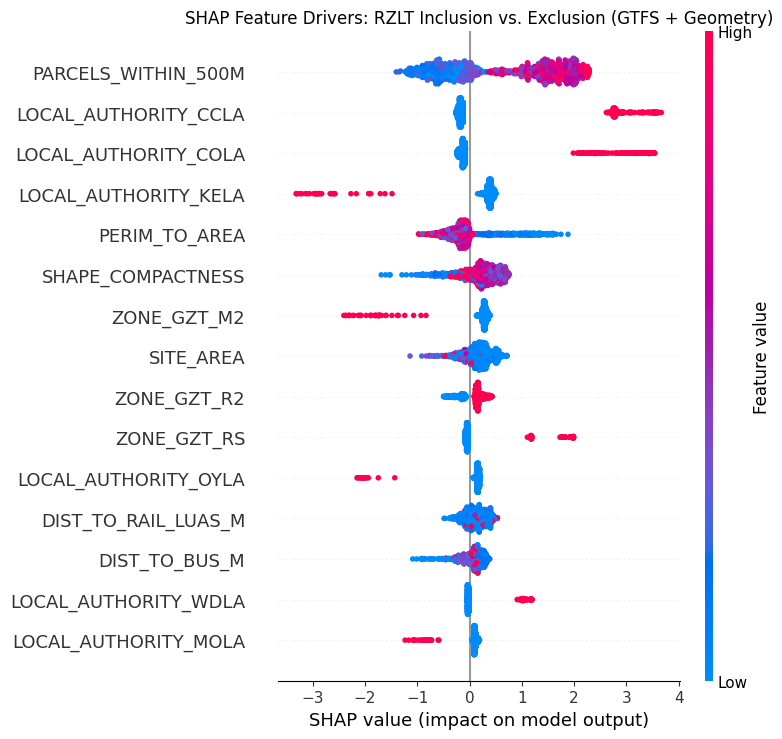

In [10]:
# ==============================================================================
# 4. SHAP EXPLAINABILITY ON LAST FOLD MODEL
# ==============================================================================
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols))
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_va)
shap_values.feature_names = feature_names

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_va, feature_names=feature_names, max_display=15, show=False)
plt.title("SHAP Feature Drivers: RZLT Inclusion vs. Exclusion (GTFS + Geometry)", fontsize=12)
plt.tight_layout()
plt.show()